# Structural Learning

Structure learning lets the data speak before we impose a directed acyclic graph (DAG) drawn from domain knowledge alone. This analysis is exploratory, not confirmatory — it asks which variables are conditionally dependent on which others, and what that pattern suggests about the causal architecture around smoking cessation and weight change.

The PC algorithm (Spirtes and Glymour, 1991) recovers a completed partially directed acyclic graph (CPDAG) from a sequence of conditional-independence (CI) tests. It assumes the Markov condition (every variable is independent of its non-descendants given its parents), faithfulness (every observed independence reflects a d-separation in the true graph), and causal sufficiency (no unmeasured common causes). Each of these assumptions will be scrutinized against the realities of this dataset (Spirtes, Glymour and Scheines, 2000).

We treat PC as an exploratory tool, not a confirmatory one. The learned graph will be used to inform — not replace — a substantive DAG grounded in study design and epidemiologic reasoning. The key methodological choices are: (1) harmonize coded missingness before any analysis, (2) reduce the variable set to plausible pre-treatment confounders, (3) use KCI as the main CI test because it handles mixed continuous/binary data without Gaussianity assumptions, and (4) impose temporal background knowledge so the algorithm cannot orient edges against the known study timeline.

## 1. Setup

Libraries, output directories and reproducibility seed.

In [4]:
import warnings; warnings.filterwarnings("ignore")
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from scipy import stats
from causallearn.search.ConstraintBased.PC import pc
from causallearn.utils.cit import fisherz, chisq, kci
from causallearn.utils.GraphUtils import GraphUtils
from causallearn.utils.PCUtils.BackgroundKnowledge import BackgroundKnowledge
from causallearn.graph.GraphNode import GraphNode
from IPython.display import Image, display

np.random.seed(42)

## 2. Data Loading

In [5]:
project_dir = Path.cwd()
data_dir = project_dir / "data"

df = pd.read_csv(data_dir / "nhefs_complete.csv")
codebook = pd.read_csv(data_dir / "nhefs_codebook.csv")

## 3. Variable Selection

We retain pre-treatment covariates that plausibly participate in the causal structure around smoking cessation and weight change. We drop identifier columns, post-treatment descendants, instruments, rare conditions, and variables with heavy missingness.

| Category | Dropped | Reason |
|---|---|---|
| Identifiers | seqn, id | No causal content |
| Post-treatment mortality | death, yrdth, modth, dadth | Recorded after the treatment window. We drop them because conditioning on a post-treatment descendant of treatment opens collider bias paths. |
| Post-treatment measures | sbp, dbp, wt82, smkintensity82_71 | sbp and dbp are measured at the 1982 follow-up. wt82 is used to compute the outcome. smkintensity82_71 is the change in smoking intensity between 1971 and 1982, so it is also a descendant of treatment |
| Instruments | school, price/tax variables, hightax82 | These affect treatment assignment (quitting smoking) but have no direct biological effect on weight change except through the treatment itself. Including instruments in a propensity score or adjustment set increases bias from unmeasured confounders, so we dropped them. |
| Rare conditions | tb, hf, polio, hepatitis, pica | Fewer than 20 cases; CI tests lack power in small cells, so we drop them |
| Heavy missingness | boweltrouble, diabetes, hbp, hbpmed, birthcontrol | Over 50% missing with no structural explanation, so they need to be dropeed |
| Dropped | pregnancies | 55% missing. Although missingness is partly structural (all men have NaN by definition), we cannot reliably distinguish women with zero pregnancies from women with unknown pregnancy history - both are stored as NaN. Recoding would introduce an arbitrary assumption about which missing values mean "none" versus "unknown", so we drop the variable entirely despite recognising it as a potential confounder for weight change. |
| Miscellaneous | birthplace, censored, older | Derived indicators. `censored` flags whether wt82 is missing, which is a post-treatment selection variable. `older` is just age > 50, redundant with age. `birthplace` has high-cardinality and in our opinion no causal role |


Additionally, we select only the 23 variables that are plausible pre-treatment confounders  plus treatment (qsmk) and outcome (wt82_71). Of the four alcohol variables we keep only alcoholpy (whether someone drinks at all) and drop the rest since they are correlated refinements of the same lifestyle signal. Of the health condition variables we keep only those with a plausible independent effect on both smoking behavior and weight (asthma, bronch, chroniccough, weakheart, tumor, nervousbreak, wtloss) and drop symptom-like variables (headache, otherpain, nerves, lackpep, infection) that are more likely consequences of smoking than baseline confounders.

In [16]:
pc_vars = [
    'age', 'sex', 'race', 'education', 'income', 'marital', 'ht', 'wt71',
    'smokeintensity', 'smokeyrs', 'exercise', 'active', 'cholesterol',
    'asthma', 'bronch', 'chroniccough', 'weakheart',
    'alcoholpy', 'wtloss', 'nervousbreak', 'tumor',
    'qsmk', 'wt82_71'
]

# We separate the outcome before any further processing
y = df['wt82_71'].copy()

df_sel = df[pc_vars].copy()

print(f"Retained {df_sel.shape[1]} variables after initial selection:")
print(list(df_sel.columns))

Retained 23 variables after initial selection:
['age', 'sex', 'race', 'education', 'income', 'marital', 'ht', 'wt71', 'smokeintensity', 'smokeyrs', 'exercise', 'active', 'cholesterol', 'asthma', 'bronch', 'chroniccough', 'weakheart', 'alcoholpy', 'wtloss', 'nervousbreak', 'tumor', 'qsmk', 'wt82_71']


## 4. Missing Data Assessment

Before running any CI tests we need to understand what is missing and why.

### 4a. Coded missingness

NHEFS uses two kinds of missingness: explicit NaN (standard) and numeric codes (e.g. `2 = MISSING`, `marital = 8`, `alcoholfreq = 5`). The PC algorithm will treat coded missing values as real observations. So we harmonize these before anything else so the CI tests work on clean data.

In [17]:
# Fix the codebook typos
codebook["variable"] = codebook["variable"].replace({
    "bithcontrol": "birthcontrol",
    "smkintensity 82_71": "smkintensity82_71"
})

df_harmonized = df_sel.copy()

# Find variables where the codebook documents "2 = MISSING"
mask_2_missing = codebook["description"].str.contains(
    r"2\s*:\s*MISSING", case=False, na=False, regex=True
)
vars_2_missing = codebook.loc[mask_2_missing, "variable"].tolist()
vars_2_missing = [c for c in vars_2_missing if c in df_harmonized.columns]

# Build the full set of coded missing values to replace
special_missing_codes = {c: 2 for c in vars_2_missing}
if "marital" in df_harmonized.columns:
    special_missing_codes["marital"] = 8
if "alcoholfreq" in df_harmonized.columns:
    special_missing_codes["alcoholfreq"] = 5

# Report what we are replacing before we do it
summary = pd.DataFrame({
    "variable": list(special_missing_codes.keys()),
    "missing_code": list(special_missing_codes.values()),
    "n_affected": [(df_harmonized[v] == code).sum()
                   for v, code in special_missing_codes.items()],
}).sort_values("n_affected", ascending=False)

print("Coded missing values to be harmonized:")
display(summary)
summary.to_csv("../outputs/tables/coded_missing_summary.csv", index=False)

# Replace coded missings with NaN
for var, miss_code in special_missing_codes.items():
    df_harmonized[var] = df_harmonized[var].replace(miss_code, np.nan)

Coded missing values to be harmonized:


,variable,missing_code,n_affected
0,alcoholpy,2,5
1,marital,8,1


### 4b. Missingness report

Now that coded missingness is harmonized, we can get an honest picture of how much data is actually missing.

In [18]:
miss = df_harmonized.isnull().sum().reset_index()
miss.columns = ['variable', 'n_missing']
miss['pct_missing'] = (miss['n_missing'] / len(df_harmonized) * 100).round(2)
miss = miss.sort_values('n_missing', ascending=False)
print(miss[miss['n_missing'] > 0].to_string(index=False))
miss.to_csv("../outputs/tables/missingness_report.csv", index=False)

   variable  n_missing  pct_missing
     income         59         3.77
cholesterol         16         1.02
  alcoholpy          5         0.32
    marital          1         0.06


### 4c. Is missingness random?

We test whether missingness is associated with treatment (`qsmk`) via chi-square, and whether outcome means differ between observed and missing groups. This will help us determine whether complete-case deletion would bias CI tests.

MCAR (Missing Completely At Random) requires that missingness is unrelated to both treatment and outcome. If either association is significant, we have at minimum MAR data, and complete-case deletion can distort the conditional independence tests PC relies on.

In [19]:
for var in ['income', 'cholesterol', 'alcoholpy', 'marital']:
    if var not in df_harmonized.columns:
        continue
    missing_flag = df_harmonized[var].isnull().astype(int)
    ct = pd.crosstab(missing_flag, df_harmonized['qsmk'])
    chi2_stat, p, _, _ = stats.chi2_contingency(ct)
    obs_mean = y[df_harmonized[var].notna()].mean()
    mis_mean = y[df_harmonized[var].isna()].mean()
    print(f"{var}:")
    print(f"  missingness vs qsmk: chi2={chi2_stat:.3f}, p={p:.4f}")
    print(f"  wt82_71 mean: observed: {obs_mean:.2f}, missing: {mis_mean:.2f}\n")

income:
  missingness vs qsmk: chi2=6.374, p=0.0116
  wt82_71 mean: observed: 2.61, missing: 3.31

cholesterol:
  missingness vs qsmk: chi2=0.864, p=0.3525
  wt82_71 mean: observed: 2.63, missing: 3.31

alcoholpy:
  missingness vs qsmk: chi2=0.000, p=1.0000
  wt82_71 mean: observed: 2.64, missing: 1.34

marital:
  missingness vs qsmk: chi2=0.308, p=0.5787
  wt82_71 mean: observed: 2.64, missing: 5.33



Results:
- income      - not MCAR (p=0.01, outcome gap 2.61 vs 3.31). People with missing income are systematically more likely to have quit smoking and to have gained more weight. Clear MAR violation. 
- cholesterol - no significant association with qsmk (p=0.35), but the outcome gap (2.63 vs 3.31) is the same size as income's. Missingness may depend on the outcome; we treat it as MAR.
- alcoholpy   - MCAR (p=1.00, tiny sample of 5). No concern.
- marital     - only 1 missing observation after harmonization. The outcome gap (2.64 vs 5.33) is large but based on a single case and therefore meaningless. No concern.

### 4d. Decision: Delete the observation containing nan 

We use deletion after harmonizing coded missingness. We don't want to impo=ute values because it introduces artificial conditional dependencies that PC would pick up as spurious edges. We intend to use KCI tests, that does not support missing values natively, so deletion is the only viable option here.
The cost is small. After harmonizing coded missings to NaN, only 81 rows are incomplete across all variables - under 5% of the sample, concentrated mostly in income (3.77%) and cholesterol (1.02%). Although income missingness is not MCAR (p=0.01), the fraction affected is small enough that the bias from dropping those rows is likely negligible.

In [21]:
df_for_pc = df_harmonized.dropna()
print(f"Sample size after dropping incomplete rows: {len(df_for_pc)} "
      f"(lost {len(df_harmonized) - len(df_for_pc)})")

Sample size after dropping incomplete rows: 1486 (lost 80)


## 5. Variable Classification

We classify variables as continuous or discrete. We verified the distributions visually and assigned types based on what the variables actually represent.

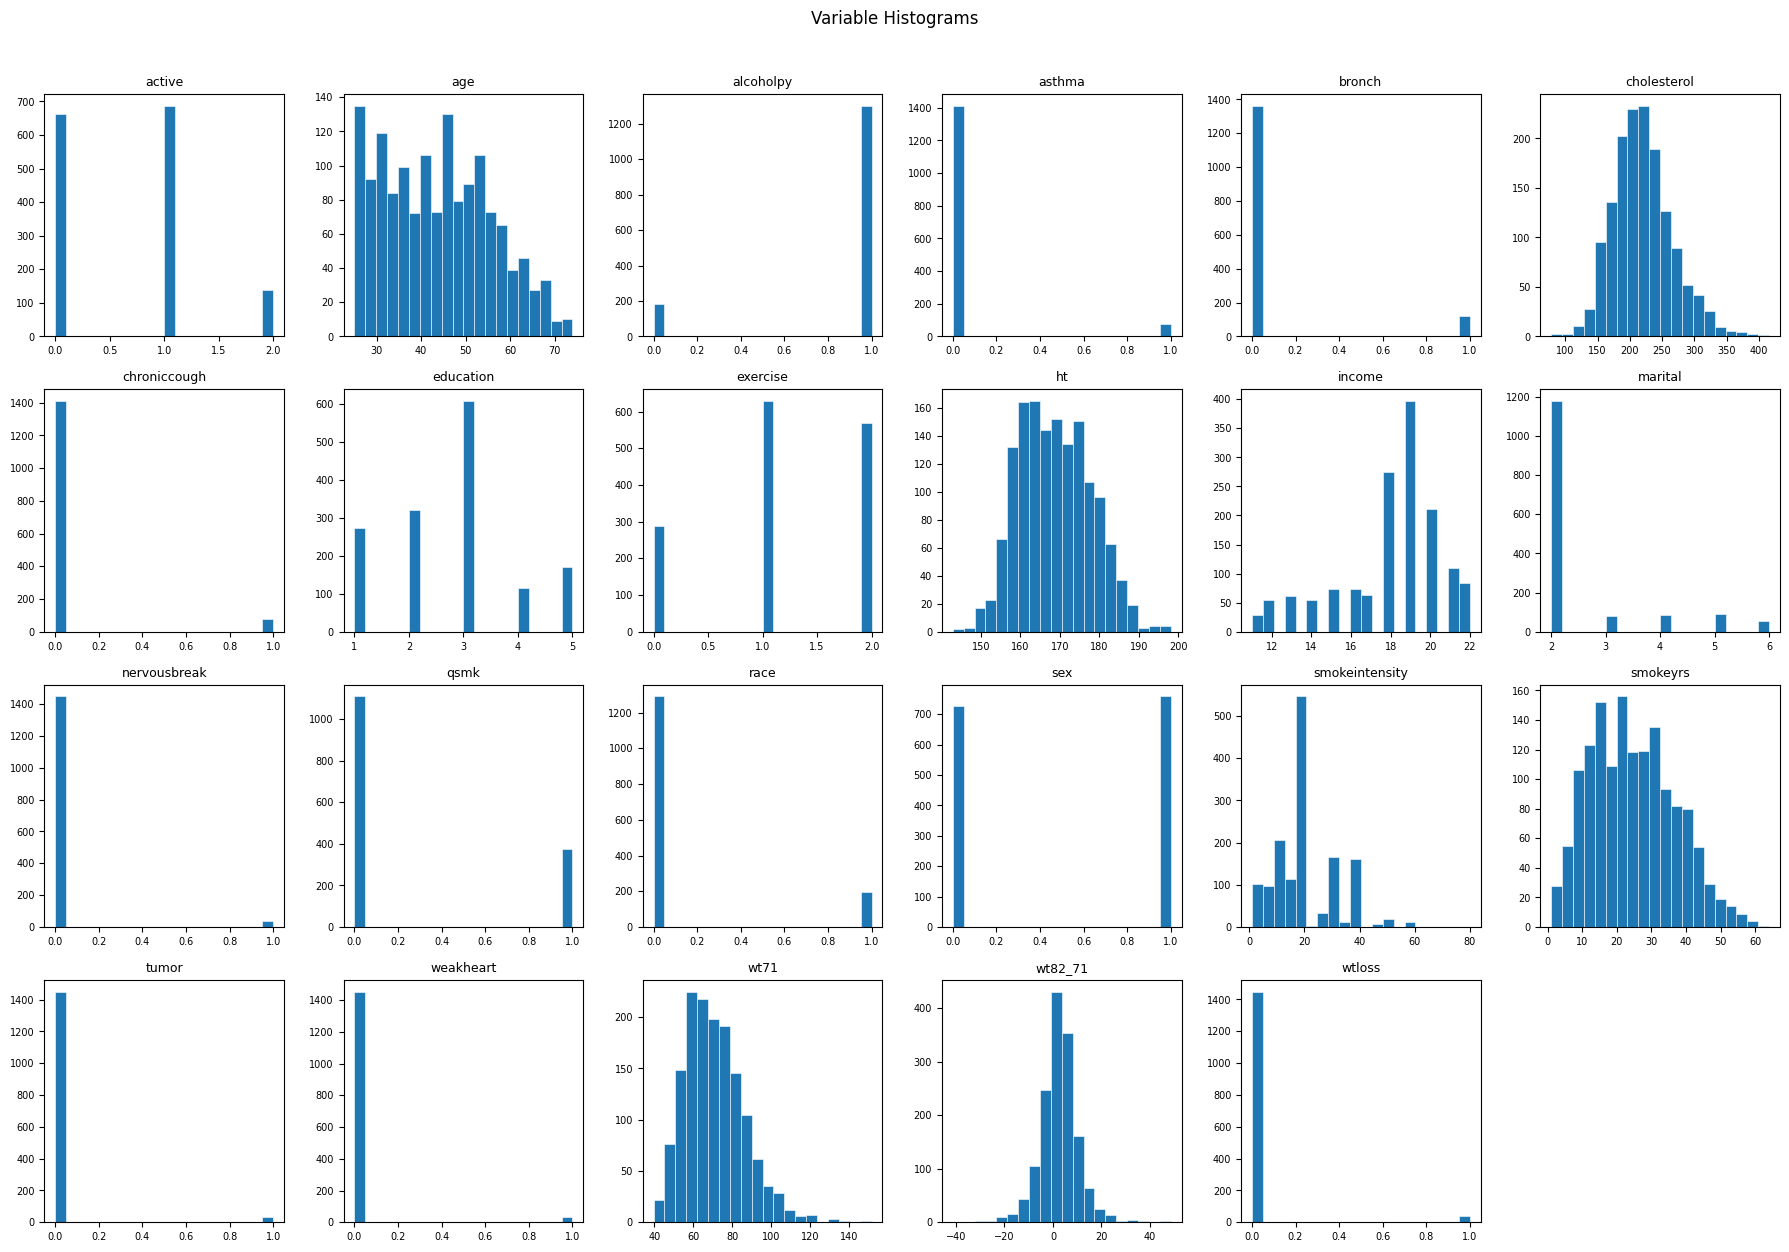

In [23]:
fig, axes = plt.subplots(nrows=6, ncols=6, figsize=(18, 18))
axes = axes.flatten()

for i, col in enumerate(sorted(df_for_pc.columns)):
    axes[i].hist(df_for_pc[col].dropna(), bins=20, edgecolor='white', linewidth=0.4)
    axes[i].set_title(col, fontsize=9)
    axes[i].set_xlabel('')
    axes[i].tick_params(labelsize=7)

# hide unused subplots
for j in range(i+1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Variable Histograms', fontsize=12, y=1.01)
plt.tight_layout()
plt.show()

In [24]:
# Based on visual inspection of histograms and common sense, income and marital have 6+ unique values but are ordinal brackets, not continuous measurements - so we force them to discrete.
continuous_vars = [
    'age', 'alcoholhowmuch', 'cholesterol', 'ht',
    'parity_cat', 'smokeintensity', 'smokeyrs', 'wt71'
]
# Remove any that were dropped earlier
continuous_vars = [v for v in continuous_vars if v in df_for_pc.columns]

discrete_vars = [
    'active', 'alcoholpy', 'allergies', 'asthma',
    'bronch', 'chroniccough', 'colitis', 'education',
    'exercise', 'hayfever', 'headache', 'income',
    'infection', 'lackpep', 'marital', 'nerves',
    'nervousbreak', 'otherpain', 'pepticulcer', 'qsmk',
    'race', 'sex', 'tumor', 'weakheart', 'wtloss'
]
discrete_vars = [v for v in discrete_vars if v in df_for_pc.columns]

print(f"Continuous ({len(continuous_vars)}): {continuous_vars}")
print(f"Discrete ({len(discrete_vars)}): {discrete_vars}")
print(f"Treatment: qsmk")
print(f"Outcome: wt82_71")

Continuous (6): ['age', 'cholesterol', 'ht', 'smokeintensity', 'smokeyrs', 'wt71']
Discrete (16): ['active', 'alcoholpy', 'asthma', 'bronch', 'chroniccough', 'education', 'exercise', 'income', 'marital', 'nervousbreak', 'qsmk', 'race', 'sex', 'tumor', 'weakheart', 'wtloss']
Treatment: qsmk
Outcome: wt82_71


## 6. Gaussian Linearity Diagnostics

Before running any PC variant we check the assumptions behind the Fisher-z test. This matters because Fisher-z is fast and widely used, but it assumes all variables are continuous and jointly Gaussian. If those assumptions are violated, the p-values can be miscalibrated and nonlinear relationships may be missed.

### 6a. Why this matters

The Fisher-z test checks whether the partial correlation between two variables, conditional on a set S, is zero. Under multivariate Gaussianity, zero partial correlation is equivalent to conditional independence (Spirtes, Glymour and Scheines, 2000, Ch. 5). If the joint distribution is not Gaussian, two problems arise: heavy tails inflate the test statistic (anti-conservative), and nonlinear relationships produce zero partial correlation even when the variables are strongly dependent.

There is a partial defense: the t-statistic underlying Fisher-z is based on sample moments, and by the central limit theorem it is approximately normal at large n even for non-Gaussian marginals. With n ~ 1500 this provides some robustness. But it does not rescue the test against heavy tails or nonlinearity.

### 6b. Univariate normality

In [26]:
norm_results = []
for c in continuous_vars:
    x = df_for_pc[c].dropna().values
    sw_stat, sw_p = stats.shapiro(x[:5000])
    sk = stats.skew(x)
    ku = stats.kurtosis(x)
    norm_results.append({
        'variable': c,
        'shapiro_p': f"{sw_p:.2e}",
        'skewness': round(sk, 2),
        'excess_kurtosis': round(ku, 2),
        'flag': '***' if (abs(sk) > 1 or ku > 2) else ''
    })

norm_df = pd.DataFrame(norm_results)
print(norm_df.to_string(index=False))

      variable shapiro_p  skewness  excess_kurtosis flag
           age  5.08e-18      0.25            -0.85     
   cholesterol  3.78e-12      0.54             0.60     
            ht  2.96e-08      0.23            -0.42     
smokeintensity  1.08e-26      0.76             0.70     
      smokeyrs  5.99e-14      0.36            -0.51     
          wt71  6.66e-18      0.78             1.01     


Every variable rejects Shapiro-Wilk at p < 0.001, but at n ~ 1500 this test is very powerful and will reject even mild departures. What matters is the shape.

The departures are mild across the board — no variable exceeds |skewness| > 1 or excess kurtosis > 2. `smokeintensity` and `wt71` are the most non-Gaussian, both right-skewed with a modest positive kurtosis, consistent with the count-like nature of smoking intensity and the right tail of baseline weight. `age` and `ht` are the closest to Gaussian with skewness under 0.3. Overall the continuous variables in this reduced set are better behaved than a naive selection would produce — `wt82_71` and `income`, which showed the most severe departures in the full variable set, are no longer in the continuous group.

This does not change our choice of KCI as the main CI test — KCI is the right tool for mixed continuous and binary data regardless of how close the continuous variables are to Gaussian. But it does mean the Fisher-z screen is a reasonable approximation here, and large discrepancies between the two tests would be surprising.

### 6c. Q-Q plots

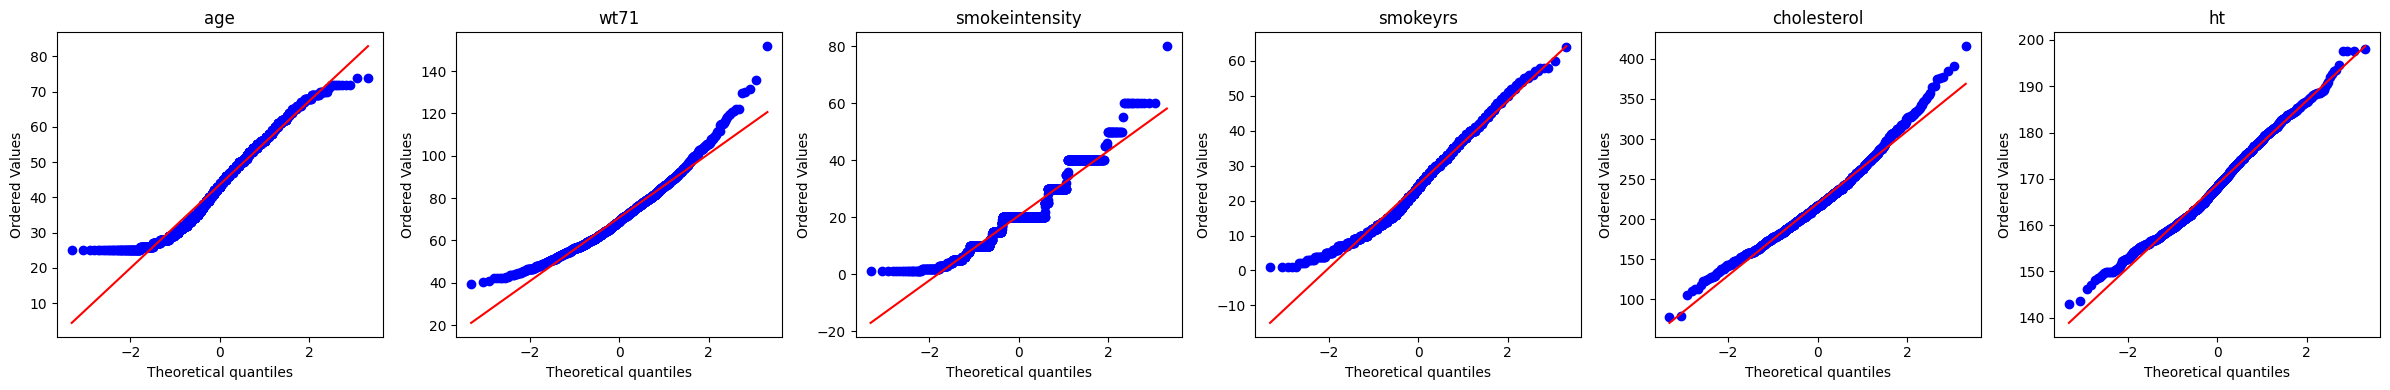

In [27]:
qq_vars = [v for v in ['age', 'wt71', 'smokeintensity', 'smokeyrs', 'cholesterol', 'ht']
           if v in df_for_pc.columns]
fig, axes = plt.subplots(1, len(qq_vars), figsize=(4 * len(qq_vars), 4))
for ax, v in zip(axes.ravel(), qq_vars):
    stats.probplot(df_for_pc[v].dropna().values, dist='norm', plot=ax)
    ax.set_title(v)
plt.tight_layout()
plt.savefig("../outputs/figures/qq_plots.png", dpi=150, bbox_inches="tight")
plt.show()

### 6d. Linearity check

If Spearman (rank-based) diverges substantially from Pearson (linear), the relationship has a nonlinear component that Fisher-z cannot detect. We compare them for the continuous variables.

In [28]:
cont_data = df_for_pc[continuous_vars].dropna()
pearson_corr = cont_data.corr(method='pearson')
spearman_corr = cont_data.corr(method='spearman')
diff = (pearson_corr - spearman_corr).abs()

pairs = []
cols = diff.columns.tolist()
for i in range(len(cols)):
    for j in range(i+1, len(cols)):
        pairs.append({
            'var1': cols[i], 'var2': cols[j],
            'pearson': round(pearson_corr.iloc[i, j], 3),
            'spearman': round(spearman_corr.iloc[i, j], 3),
            'abs_diff': round(diff.iloc[i, j], 3)
        })

lin_df = pd.DataFrame(pairs).sort_values('abs_diff', ascending=False)
print(lin_df.head(10).to_string(index=False))
lin_df.to_csv("../outputs/tables/linearity_check.csv", index=False)

          var1           var2  pearson  spearman  abs_diff
           age           wt71    0.016     0.050     0.034
   cholesterol       smokeyrs    0.207     0.239     0.033
      smokeyrs           wt71    0.053     0.082     0.029
            ht smokeintensity    0.199     0.220     0.021
            ht           wt71    0.496     0.516     0.020
           age    cholesterol    0.282     0.301     0.019
   cholesterol           wt71    0.120     0.136     0.016
smokeintensity           wt71    0.100     0.114     0.014
           age             ht   -0.084    -0.071     0.013
           age       smokeyrs    0.868     0.878     0.010


### 6e. Verdict

The Gaussian linearity assumption is approximately met for this reduced variable set. No continuous variable exceeds |skewness| > 1 or excess kurtosis > 2, and all Pearson–Spearman differences are below 0.035, suggesting relationships are approximately linear and monotone. `smokeintensity` is the most non-Gaussian, consistent with its discrete-like distribution, but the departure is not severe enough to invalidate a Gaussian test on its own.

We use KCI as our single CI test rather than Fisher-z because of the fact that our dataset is mixed: roughly half the variables are binary, and Fisher-z is simply the wrong test for those regardless of how well-behaved the continuous variables are. KCI handles both types correctly without any distributional assumptions.

## 7. Temporal Background Knowledge

Before running PC we encode what we know from the study design. All baseline covariates were measured in 1971, treatment (`qsmk`) occurred between 1971–1982, and the outcome (`wt82_71`) was measured in 1982. PC is free to learn any edge direction consistent with this ordering, but cannot orient edges backwards in time - weight change cannot cause past quitting decisions, and baseline variables cannot be caused by either treatment or outcome.

In [29]:
# Encode what we know from study design.
# Baseline covariates (tier 0) precede treatment (tier 1) which precedes
# outcome (tier 2). PC cannot orient edges backwards in time.
def build_background_knowledge(pretreat, treatment='qsmk', outcome='wt82_71',
                               require_treatment_to_outcome=False):
    bk = BackgroundKnowledge()
    nodes = {v: GraphNode(v) for v in pretreat + [treatment, outcome]}
    for v in pretreat:
        bk.add_node_to_tier(nodes[v], 0)
    bk.add_node_to_tier(nodes[treatment], 1)
    bk.add_node_to_tier(nodes[outcome], 2)
    if require_treatment_to_outcome:
        bk.add_required_by_node(nodes[treatment], nodes[outcome])
    return bk

pretreat = [v for v in pc_vars if v not in ['qsmk', 'wt82_71']]
bk = build_background_knowledge(pretreat, treatment='qsmk', outcome='wt82_71')

print(f"Baseline covariates (tier 0): {pretreat}")
print("Treatment (tier 1): qsmk")
print("Outcome (tier 2): wt82_71")

Baseline covariates (tier 0): ['age', 'sex', 'race', 'education', 'income', 'marital', 'ht', 'wt71', 'smokeintensity', 'smokeyrs', 'exercise', 'active', 'cholesterol', 'asthma', 'bronch', 'chroniccough', 'weakheart', 'alcoholpy', 'wtloss', 'nervousbreak', 'tumor']
Treatment (tier 1): qsmk
Outcome (tier 2): wt82_71


## 8. PC with KCI — Main Result

KCI (Zhang et al., 2011) is our main CI test because it makes no Gaussianity or linearity assumptions and handles mixed continuous/binary data correctly. It embeds variables in a reproducing kernel Hilbert space and tests independence using kernel statistics, which can detect nonlinear relationships that Fisher-z misses.

We use the same variable set and temporal background knowledge as the Fisher-z screen, and we pass the full harmonized dataset with MVPC enabled so that rows with missing values are retained rather than dropped. KCI scales O(n³) which makes it slow, but by keeping the variable set small (24 variables) we avoid the combinatorial explosion of conditioning sets that would make a larger run intractable.

In [ ]:
# KCI does not support NaN even with mvpc=True — the kernel distance
# computation requires complete cases. We drop incomplete rows here.
# This loses at most ~5% of observations (income + cholesterol missingness)
# which is acceptable given the small amount missing.
df_kci = df_for_pc[pc_vars].dropna()
kci_data = df_kci.values.astype(float)

print(f"KCI sample size after dropping incomplete rows: {len(df_kci)} "
      f"(lost {len(df_for_pc) - len(df_kci)})")

cg_kci = pc(
    kci_data,
    alpha=0.05,
    indep_test=kci,
    stable=True,
    background_knowledge=bk,
    node_names=pc_vars,
)

KCI sample size after dropping incomplete rows: 1486 (lost 0)


  0%|          | 0/23 [00:00<?, ?it/s]

In [ ]:
pdy_kci = GraphUtils.to_pydot(cg_kci.G, labels=pc_vars)
pdy_kci.write_png("../outputs/figures/cpdag_kci_05_tiered.png")
display(Image("../outputs/figures/cpdag_kci_05_tiered.png"))

e_kci = extract_edges(cg_kci, pc_vars, ['qsmk', 'wt82_71'])
print("\nTiered KCI alpha=0.05 — edges involving qsmk or wt82_71:")
for e in e_kci: print(f"  {e}")
if not e_kci: print("  (no edges involving qsmk or wt82_71)")

pd.DataFrame({'method': 'KCI_tiered', 'alpha': 0.05,
              'edge': e_kci if e_kci else ['(none)']}).to_csv(
    "../outputs/tables/edges_kci_tiered.csv", index=False)

Running tiered KCI on 1566 observations and 24 variables.
This will take several minutes...



AssertionError: Input data contains NaN. Please check.

## 11. Summary Comparison

We compare the treatment and outcome neighborhood across all three methods. Edges that appear in both the Fisher-z screen and the KCI run are the most credible — they survive both a parametric and a nonparametric test under the same temporal constraints.

In [ ]:
def get_neighbors(cg, labels, node):
    """Get all neighbors of a node with their edge directions."""
    if node not in labels:
        return 'N/A'
    g = cg.G.graph
    idx = labels.index(node)
    neighbors = []
    for j in range(len(labels)):
        if j == idx: continue
        if g[idx, j] != 0 or g[j, idx] != 0:
            if g[idx, j] == -1 and g[j, idx] == 1:
                neighbors.append(f"{node} -> {labels[j]}")
            elif g[idx, j] == 1 and g[j, idx] == -1:
                neighbors.append(f"{labels[j]} -> {node}")
            elif g[idx, j] == -1 and g[j, idx] == -1:
                neighbors.append(f"{node} -- {labels[j]}")
            else:
                neighbors.append(f"{node} ? {labels[j]}")
    return "; ".join(neighbors) if neighbors else "(isolated)"

summary_rows = []
for label, cg_obj, lbl_list, alpha_val in [
    ('Fisher-z (screen)', cg_fz05, pc_vars, 0.05),
    ('Fisher-z (screen)', cg_fz01, pc_vars, 0.01),
    ('Chi-square (discrete only)', cg_chi, chisq_vars, 0.05),
    ('KCI (main result)', cg_kci, pc_vars, 0.05),
]:
    summary_rows.append({
        'method': label, 'alpha': alpha_val,
        'qsmk_neighbors': get_neighbors(cg_obj, lbl_list, 'qsmk'),
        'wt82_71_neighbors': get_neighbors(cg_obj, lbl_list, 'wt82_71')
    })

summary_df = pd.DataFrame(summary_rows)
print(summary_df.to_string(index=False))
summary_df.to_csv("../outputs/tables/edge_comparison.csv", index=False)

The most useful comparison is between the temporally constrained Fisher-z screen and the temporally constrained KCI graph. Fisher-z is fast but approximate; KCI is slower but makes no distributional assumptions. Edges consistent across both under the same temporal constraints are the strongest candidates for inclusion in the final DAG.

Discrepancies between methods are expected and informative — they may reflect nonlinear relationships that Fisher-z missed, or underpowered KCI tests in smaller conditioning sets. Neither graph should be read mechanically; both feed into the substantive expert-specified DAG that will anchor the causal analysis.

## 12. Conclusion

The main lesson from this notebook is that unconstrained PC applied mechanically to mixed observational data produces scientifically implausible graphs. Three design choices make our graphs more trustworthy:

1. **Harmonized missingness** — we recoded numeric missing codes to NaN before any CI tests, so MVPC sees real missingness rather than spurious values.
2. **Smaller, principled variable set** — we restricted PC to 24 plausible pre-treatment confounders plus treatment and outcome, avoiding the combinatorial explosion of CI tests that makes larger graphs unreliable.
3. **Temporal background knowledge** — we told PC that baseline variables precede treatment, and treatment precedes weight change. This rules out obviously implausible edge directions by construction.

The tiered KCI run is the preferred exploratory result. It is the most technically correct for our mixed continuous/binary data, uses the full sample, and respects the study chronology. The Fisher-z and Chi-square graphs serve as fast cross-checks.

For the final project, the learned structure informs but does not replace a substantive DAG. Any edge in the KCI graph that is also consistent with domain knowledge and the study design is a strong candidate for inclusion. Edges that appear only in the data-driven graph, with no epidemiologic justification, should be treated with skepticism.

## 13. References

1. Spirtes P, Glymour C. An algorithm for fast recovery of sparse causal graphs. *Social Science Computer Review* 9(1):62-72, 1991.
2. Spirtes P, Glymour C, Scheines R. *Causation, Prediction, and Search*. 2nd ed. MIT Press, 2000.
3. Colombo D, Maathuis MH. Order-independent constraint-based causal structure learning. *Journal of Machine Learning Research* 15:3921-3962, 2014.
4. Tu R, Zhang C, Ackermann P, Mohan K, Kjellstrom H, Zhang K. Causal discovery in the presence of missing data. *Proceedings of Machine Learning Research* 89:1762-1770, 2019.
5. Gain A, Shpitser I. Structure learning under missing data. *Proceedings of Machine Learning Research* 72:121-132, 2018.
6. Zhang K, Peters J, Janzing D, Scholkopf B. Kernel-based conditional independence test and application in causal discovery. *UAI*, 804-813, 2011.
7. Hernán MA, Robins JM. *Causal Inference: What If*. Chapman and Hall/CRC, 2020.
8. Glymour C, Zhang K, Spirtes P. Review of causal discovery methods based on graphical models. *Frontiers in Genetics* 10:524, 2019.
9. Zheng Y, Huang B, Chen W, Ramsey J, Gong M, Cai R, Shimizu S, Spirtes P, Zhang K. causal-learn: Causal discovery in Python. *Journal of Machine Learning Research* 25(60):1-8, 2024.
10. Strobl EV, Zhang K, Visweswaran S. Approximate kernel-based conditional independence tests for fast discovery of conditional independencies. *Journal of Causal Inference* 7(1), 2019.
11. Chickering DM. Optimal structure identification with greedy search. *Journal of Machine Learning Research* 3:507-554, 2002.
12. Colombo D, Maathuis MH, Kalisch M, Richardson TS. Learning high-dimensional directed acyclic graphs with latent and selection variables. *Annals of Statistics* 40(1):294-321, 2012.